# Aprendizaje por Refuerzo Profundo para el Brazo Robotico de Ajedrez

Este cuadernillo implementa un modulo demostrativo y defendible de **Deep Reinforcement Learning** para el proyecto.

La idea central es segura para el hardware:

- El agente **no controla servomotores reales**.
- El agente aprende una politica de navegacion en simulacion usando `puntos.txt` como mapa calibrado.
- Las calibraciones reales no se reemplazan.
- Se exportan resultados experimentales a `outputs/`, incluyendo `puntos_generados.txt`, rutas aprendidas, graficas y modelo entrenado.

`puntos.txt` define el entorno fisico real, mientras que el agente aprende estrategias de movimiento sobre ese entorno sin arriesgar el brazo.

## 1. Instalacion de librerias

Ejecuta esta celda en el entorno de Jupyter de la universidad para instalar dependencias.

In [1]:
%pip install gymnasium torch torchvision numpy matplotlib pandas seaborn tqdm ipywidgets


   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 914.9/914.9 kB 4.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------- -------------------- 1.0/2.2 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 4.9 MB/s  0:00:00

   ---------------------------------------- 0/3 [widgetsnbextension]
   ---------------------------------------- 0/3 [widgetsnbextension]
   ---------------------------------------- 0/3 [widgetsnbextension]
   ---------------------------------------- 0/3 [widgetsnbextension]
   ---------------------------------------- 0/3 [widgetsnbextension]
   ---------------------------------------- 0/3 [widgetsnbextension]
   ------------- -------------------------- 1/3 [jupyterlab_widgets]
   ------------- -------------------------- 1/3 [jupyterlab_widgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   ----------------


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports y configuracion general

In [3]:
from pathlib import Path
from collections import deque, namedtuple
import json
import math
import random
import time

import gymnasium as gym
from gymnasium import spaces

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import trange

import torch
import torch.nn as nn
import torch.optim as optim


def encontrar_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for p in [start, *start.parents]:
        if (p / "mapeos.txt").exists():
            return p
    return Path.cwd()


ROOT = encontrar_root()
RL_DIR = ROOT / "Aprendizaje_Por_Refuerzo"
OUTPUT_DIR = RL_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PUNTOS_PATH = ROOT / "mapeos.txt"
MODEL_PATH = OUTPUT_DIR / "modelo_dqn_brazo.pth"
HISTORY_PATH = OUTPUT_DIR / "historial_entrenamiento.json"
ROUTES_PATH = OUTPUT_DIR / "rutas_generadas.json"
PUNTOS_GENERADOS_PATH = OUTPUT_DIR / "puntos_generados.txt"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("ROOT:", ROOT)
print("Puntos calibrados:", PUNTOS_PATH)
print("Outputs:", OUTPUT_DIR)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

ROOT: /notebook
Puntos calibrados: /notebook/mapeos.txt
Outputs: /notebook/Aprendizaje_Por_Refuerzo/outputs
Device: cuda
GPU: NVIDIA GeForce RTX 3090


## 3. Carga y validacion de `mapeos.txt`

In [4]:
def cargar_puntos(path=PUNTOS_PATH):
    puntos = {}
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"No existe el archivo: {path}")

    with open(path, "r", encoding="utf-8") as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith("#") or ":" not in linea:
                continue
            casilla, valores_txt = linea.split(":", 1)
            valores = [v.strip() for v in valores_txt.split(",")]
            if len(valores) == 3:
                puntos[casilla.strip().upper()] = np.array([float(v) for v in valores], dtype=np.float32)
    return puntos


def validar_puntos(puntos):
    faltantes = []
    for file in "ABCDEFGH":
        for rank in "12345678":
            sq = file + rank
            if sq not in puntos:
                faltantes.append(sq)
    if faltantes:
        raise ValueError("Faltan casillas calibradas: " + ", ".join(faltantes))
    return True


def square_to_rc(square):
    square = square.upper()
    col = ord(square[0]) - ord("A")
    row = int(square[1]) - 1
    return row, col


def rc_to_square(row, col):
    return chr(ord("A") + int(col)) + str(int(row) + 1)


puntos = cargar_puntos(PUNTOS_PATH)
validar_puntos(puntos)

SQUARES = [rc_to_square(r, c) for r in range(8) for c in range(8)]
ANGLE_MIN = np.min(np.stack([puntos[sq] for sq in SQUARES]), axis=0)
ANGLE_MAX = np.max(np.stack([puntos[sq] for sq in SQUARES]), axis=0)
ANGLE_RANGE = np.maximum(ANGLE_MAX - ANGLE_MIN, 1e-6)

# HOME virtual aproximado desde el firmware Arduino: base, codo, hombro.
HOME_NODE = "HOME"
HOME_ANGLES = np.array([112.0, 100.0, 110.0], dtype=np.float32)

print("Total de puntos:", len(puntos))
print("Rango angular minimo:", ANGLE_MIN)
print("Rango angular maximo:", ANGLE_MAX)
pd.DataFrame(
    [{"casilla": sq, "base": puntos[sq][0], "codo": puntos[sq][1], "hombro": puntos[sq][2]} for sq in SQUARES]
).head()

Total de puntos: 64
Rango angular minimo: [50.9 29.5 21.8]
Rango angular maximo: [164.5 136.5 132. ]


,casilla,base,codo,hombro
0,A1,87.900002,136.500000,21.799999
1,B1,94.199997,131.000000,27.500000
2,C1,99.800003,124.699997,31.500000
3,D1,105.500000,121.500000,30.000000
4,E1,111.699997,121.500000,30.000000


## 4. Visualizacion del mapa calibrado

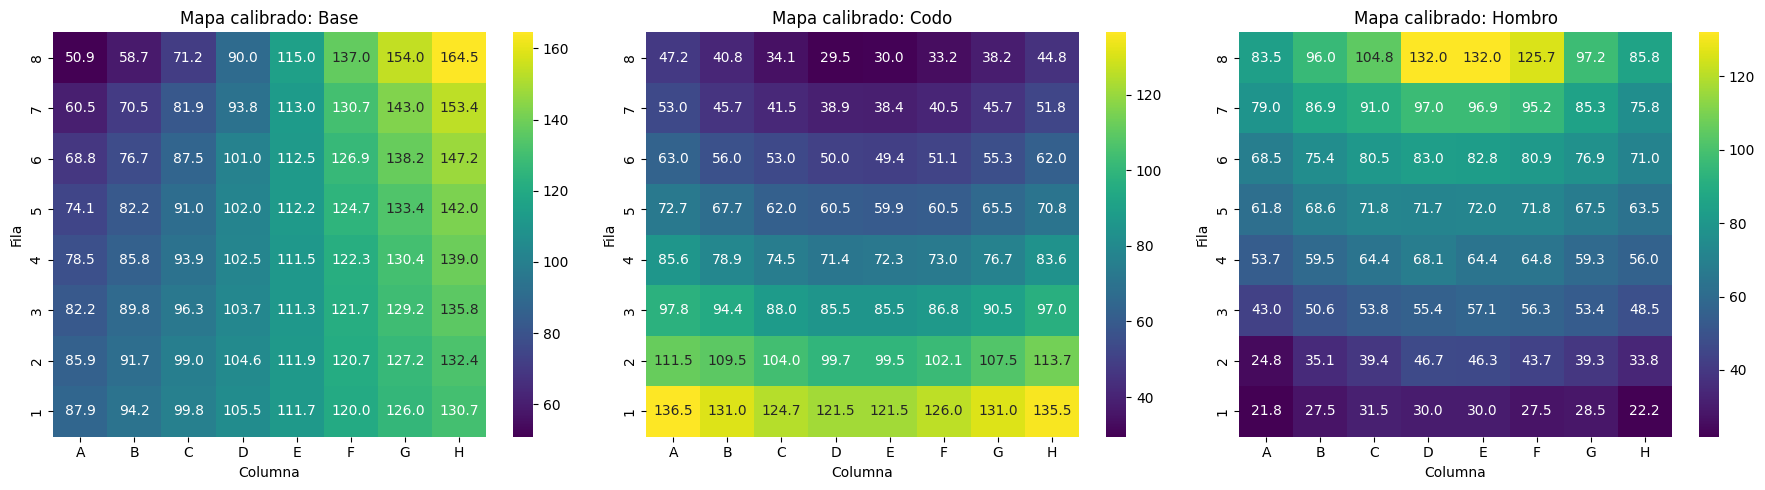

In [5]:
def matriz_valor_por_casilla(indice_angulo):
    mat = np.zeros((8, 8), dtype=float)
    for sq in SQUARES:
        r, c = square_to_rc(sq)
        mat[7 - r, c] = puntos[sq][indice_angulo]
    return mat


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titulos = ["Base", "Codo", "Hombro"]
for i, ax in enumerate(axes):
    sns.heatmap(
        matriz_valor_por_casilla(i),
        annot=True,
        fmt=".1f",
        cmap="viridis",
        xticklabels=list("ABCDEFGH"),
        yticklabels=list("87654321"),
        ax=ax,
    )
    ax.set_title(f"Mapa calibrado: {titulos[i]}")
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
plt.tight_layout()
plt.show()

## 5. Entorno Gymnasium

El agente se mueve en un tablero simulado basado en las 64 casillas calibradas.

Acciones:

- `0..7`: moverse a una casilla vecina en 8 direcciones.
- `8`: ir al nodo virtual `HOME`, equivalente a una estrategia segura.
- `9`: si esta en `HOME`, ir al objetivo; si esta en el objetivo, finalizar.

La recompensa premia llegar al objetivo, reducir distancia, usar trayectorias suaves y evitar pasos innecesarios.

In [6]:
class BrazoAjedrezEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    ACTIONS = {
        0: (1, 0),    # arriba
        1: (-1, 0),   # abajo
        2: (0, -1),   # izquierda
        3: (0, 1),    # derecha
        4: (1, -1),   # diagonal arriba izquierda
        5: (1, 1),    # diagonal arriba derecha
        6: (-1, -1),  # diagonal abajo izquierda
        7: (-1, 1),   # diagonal abajo derecha
        8: "HOME",
        9: "FINISH_OR_TARGET_FROM_HOME",
    }

    def __init__(self, puntos, max_steps=35, seed=SEED):
        super().__init__()
        self.puntos = puntos
        self.squares = [rc_to_square(r, c) for r in range(8) for c in range(8)]
        self.max_steps = max_steps
        self.rng = random.Random(seed)

        self.action_space = spaces.Discrete(10)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(14,), dtype=np.float32)

        self.current = None
        self.target = None
        self.previous_square_before_home = None
        self.steps = 0
        self.route = []

    def _angles(self, node):
        if node == HOME_NODE:
            return HOME_ANGLES
        return self.puntos[node]

    def _grid_distance(self, a, b):
        if a == HOME_NODE:
            return 4.0
        ar, ac = square_to_rc(a)
        br, bc = square_to_rc(b)
        return abs(ar - br) + abs(ac - bc)

    def _angular_distance(self, a, b):
        return float(np.linalg.norm((self._angles(a) - self._angles(b)) / ANGLE_RANGE))

    def _obs(self):
        if self.current == HOME_NODE:
            row, col = 3.5, 3.5
        else:
            row, col = square_to_rc(self.current)
        tr, tc = square_to_rc(self.target)
        current_angles = (self._angles(self.current) - ANGLE_MIN) / ANGLE_RANGE
        target_angles = (self._angles(self.target) - ANGLE_MIN) / ANGLE_RANGE
        grid_dist = self._grid_distance(self.current, self.target) / 14.0
        angular_dist = min(self._angular_distance(self.current, self.target) / 3.0, 1.0)
        is_home = 1.0 if self.current == HOME_NODE else 0.0
        step_frac = self.steps / self.max_steps
        return np.array([
            row / 7.0,
            col / 7.0,
            tr / 7.0,
            tc / 7.0,
            *current_angles.tolist(),
            *target_angles.tolist(),
            grid_dist,
            angular_dist,
            is_home,
            step_frac,
        ], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current = self.rng.choice(self.squares)
        self.target = self.rng.choice(self.squares)
        while self.target == self.current:
            self.target = self.rng.choice(self.squares)
        self.previous_square_before_home = None
        self.steps = 0
        self.route = [self.current]
        return self._obs(), {"current": self.current, "target": self.target}

    def reset_task(self, origen, destino):
        self.current = origen.upper()
        self.target = destino.upper()
        self.previous_square_before_home = None
        self.steps = 0
        self.route = [self.current]
        return self._obs(), {"current": self.current, "target": self.target}

    def step(self, action):
        prev = self.current
        prev_grid = self._grid_distance(prev, self.target)
        prev_ang = self._angular_distance(prev, self.target)
        invalid = False
        terminated = False

        self.steps += 1

        if action in range(8):
            if self.current == HOME_NODE:
                invalid = True
            else:
                dr, dc = self.ACTIONS[action]
                r, c = square_to_rc(self.current)
                nr, nc = r + dr, c + dc
                if 0 <= nr < 8 and 0 <= nc < 8:
                    self.current = rc_to_square(nr, nc)
                else:
                    invalid = True
        elif action == 8:
            if self.current != HOME_NODE:
                self.previous_square_before_home = self.current
                self.current = HOME_NODE
            else:
                invalid = True
        elif action == 9:
            if self.current == HOME_NODE:
                self.current = self.target
            elif self.current == self.target:
                terminated = True
            else:
                invalid = True

        if self.current != prev:
            self.route.append(self.current)

        new_grid = self._grid_distance(self.current, self.target)
        new_ang = self._angular_distance(self.current, self.target)
        angular_jump = self._angular_distance(prev, self.current)

        reward = -0.7
        reward += 2.5 * (prev_grid - new_grid)
        reward += 1.5 * (prev_ang - new_ang)
        reward -= 0.08 * angular_jump

        if invalid:
            reward -= 8.0

        if action == 8 and prev_ang > 1.2:
            reward += 1.5

        if action == 9 and prev == HOME_NODE:
            reward += 8.0

        if terminated:
            reward += 120.0

        truncated = self.steps >= self.max_steps
        if truncated and self.current != self.target:
            reward -= 30.0

        info = {
            "current": self.current,
            "target": self.target,
            "route": list(self.route),
            "success": terminated and self.current == self.target,
            "grid_distance": new_grid,
            "angular_distance": new_ang,
            "invalid": invalid,
        }
        return self._obs(), float(reward), terminated, truncated, info

    def render(self):
        print(" -> ".join(self.route), "| objetivo:", self.target)


env = BrazoAjedrezEnv(puntos)
obs, info = env.reset()
print("Observation shape:", obs.shape)
print(info)

Observation shape: (14,)
{'current': 'G2', 'target': 'D1'}


## 6. Red neuronal DQN y Replay Buffer

In [7]:
Transition = namedtuple("Transition", ["state", "action", "reward", "next_state", "done"])


class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, *args):
        self.buffer.append(Transition(*args))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        return Transition(*zip(*batch))

    def __len__(self):
        return len(self.buffer)


class DQN(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim),
        )

    def forward(self, x):
        return self.net(x)


def seleccionar_accion(policy_net, state, epsilon):
    if random.random() < epsilon:
        return env.action_space.sample()
    with torch.no_grad():
        state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        q_values = policy_net(state_t)
        return int(torch.argmax(q_values, dim=1).item())


state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
policy_net = DQN(state_dim, action_dim).to(device)
target_net = DQN(state_dim, action_dim).to(device)
target_net.load_state_dict(policy_net.state_dict())

print(policy_net)

DQN(
  (net): Sequential(
    (0): Linear(in_features=14, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 7. Configuracion de entrenamiento

In [8]:
# Puedes subir EPISODES en el entorno con GPU de la universidad.
EPISODES = 6000
MAX_STEPS = 35
BATCH_SIZE = 256
BUFFER_SIZE = 120_000
GAMMA = 0.985
LEARNING_RATE = 2.5e-4
TARGET_UPDATE_EVERY = 250
TRAIN_START = 1500

EPS_START = 1.0
EPS_END = 0.04
EPS_DECAY_EPISODES = int(EPISODES * 0.70)

optimizer = optim.AdamW(policy_net.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
loss_fn = nn.SmoothL1Loss()
replay = ReplayBuffer(BUFFER_SIZE)


def epsilon_por_episodio(ep):
    frac = min(ep / EPS_DECAY_EPISODES, 1.0)
    return EPS_END + (EPS_START - EPS_END) * (1.0 - frac) ** 2


def optimizar_modelo():
    if len(replay) < max(TRAIN_START, BATCH_SIZE):
        return None

    batch = replay.sample(BATCH_SIZE)
    states = torch.tensor(np.array(batch.state), dtype=torch.float32, device=device)
    actions = torch.tensor(batch.action, dtype=torch.long, device=device).unsqueeze(1)
    rewards = torch.tensor(batch.reward, dtype=torch.float32, device=device).unsqueeze(1)
    next_states = torch.tensor(np.array(batch.next_state), dtype=torch.float32, device=device)
    dones = torch.tensor(batch.done, dtype=torch.float32, device=device).unsqueeze(1)

    q_values = policy_net(states).gather(1, actions)
    with torch.no_grad():
        next_actions = policy_net(next_states).argmax(dim=1, keepdim=True)
        next_q = target_net(next_states).gather(1, next_actions)
        targets = rewards + GAMMA * next_q * (1.0 - dones)

    loss = loss_fn(q_values, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(policy_net.parameters(), 1.0)
    optimizer.step()
    return float(loss.item())


print("Episodios:", EPISODES)
print("Device:", device)

Episodios: 6000
Device: cuda


## 8. Entrenamiento

In [9]:
def entrenar_dqn():
    global env
    env = BrazoAjedrezEnv(puntos, max_steps=MAX_STEPS, seed=SEED)
    history = {
        "episode": [],
        "reward": [],
        "loss": [],
        "steps": [],
        "success": [],
        "epsilon": [],
    }

    progress = trange(1, EPISODES + 1, desc="Entrenando DQN")
    for ep in progress:
        state, info = env.reset()
        total_reward = 0.0
        losses = []
        success = False

        epsilon = epsilon_por_episodio(ep)

        for step in range(MAX_STEPS):
            action = seleccionar_accion(policy_net, state, epsilon)
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            replay.push(state, action, reward, next_state, done)

            loss = optimizar_modelo()
            if loss is not None:
                losses.append(loss)

            state = next_state
            total_reward += reward
            success = bool(info.get("success", False))

            if done:
                break

        if ep % TARGET_UPDATE_EVERY == 0:
            target_net.load_state_dict(policy_net.state_dict())

        avg_loss = float(np.mean(losses)) if losses else np.nan
        history["episode"].append(ep)
        history["reward"].append(float(total_reward))
        history["loss"].append(avg_loss)
        history["steps"].append(step + 1)
        history["success"].append(int(success))
        history["epsilon"].append(float(epsilon))

        if ep % 100 == 0:
            recent_reward = np.mean(history["reward"][-100:])
            recent_success = np.mean(history["success"][-100:])
            progress.set_postfix({
                "reward100": f"{recent_reward:.1f}",
                "success100": f"{recent_success:.2f}",
                "eps": f"{epsilon:.2f}",
            })

    return history


history = entrenar_dqn()
print("Entrenamiento terminado.")

Entrenando DQN:   0%|          | 0/6000 [00:00<?, ?it/s]

Entrenamiento terminado.


## 9. Graficas de recompensa, perdida y exito

/tmp/ipykernel_212/4003749130.py:19: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  axes[0, 1].plot(ep, rolling_mean(pd.Series(losses).fillna(method="bfill").fillna(0), 100), linewidth=2, label="Media movil 100")


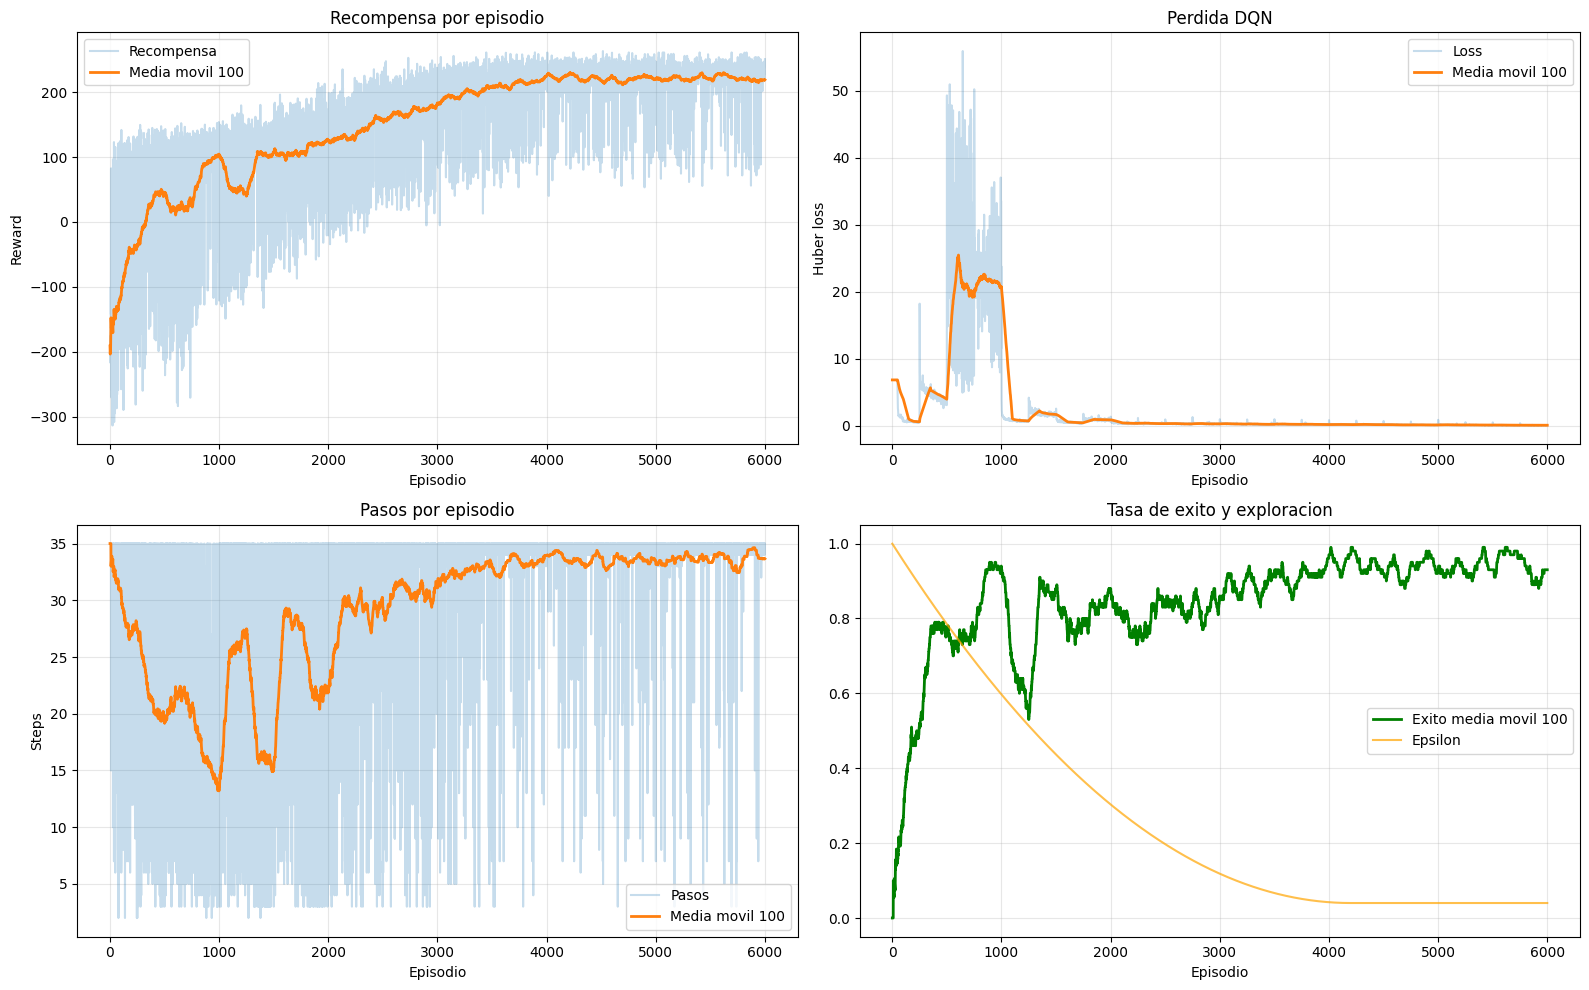

In [10]:
def rolling_mean(values, window=100):
    return pd.Series(values).rolling(window, min_periods=1).mean().to_numpy()


def graficar_historial(history):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    ep = history["episode"]

    axes[0, 0].plot(ep, history["reward"], alpha=0.25, label="Recompensa")
    axes[0, 0].plot(ep, rolling_mean(history["reward"], 100), linewidth=2, label="Media movil 100")
    axes[0, 0].set_title("Recompensa por episodio")
    axes[0, 0].set_xlabel("Episodio")
    axes[0, 0].set_ylabel("Reward")
    axes[0, 0].grid(alpha=0.3)
    axes[0, 0].legend()

    losses = np.array(history["loss"], dtype=float)
    axes[0, 1].plot(ep, losses, alpha=0.25, label="Loss")
    axes[0, 1].plot(ep, rolling_mean(pd.Series(losses).fillna(method="bfill").fillna(0), 100), linewidth=2, label="Media movil 100")
    axes[0, 1].set_title("Perdida DQN")
    axes[0, 1].set_xlabel("Episodio")
    axes[0, 1].set_ylabel("Huber loss")
    axes[0, 1].grid(alpha=0.3)
    axes[0, 1].legend()

    axes[1, 0].plot(ep, history["steps"], alpha=0.25, label="Pasos")
    axes[1, 0].plot(ep, rolling_mean(history["steps"], 100), linewidth=2, label="Media movil 100")
    axes[1, 0].set_title("Pasos por episodio")
    axes[1, 0].set_xlabel("Episodio")
    axes[1, 0].set_ylabel("Steps")
    axes[1, 0].grid(alpha=0.3)
    axes[1, 0].legend()

    axes[1, 1].plot(ep, rolling_mean(history["success"], 100), color="green", linewidth=2, label="Exito media movil 100")
    axes[1, 1].plot(ep, history["epsilon"], color="orange", alpha=0.7, label="Epsilon")
    axes[1, 1].set_title("Tasa de exito y exploracion")
    axes[1, 1].set_xlabel("Episodio")
    axes[1, 1].set_ylim(-0.05, 1.05)
    axes[1, 1].grid(alpha=0.3)
    axes[1, 1].legend()

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "graficas_entrenamiento.png", dpi=160)
    plt.show()


graficar_historial(history)

## 10. Guardar modelo e historial

In [11]:
torch.save({
    "model_state_dict": policy_net.state_dict(),
    "target_state_dict": target_net.state_dict(),
    "state_dim": state_dim,
    "action_dim": action_dim,
    "config": {
        "episodes": EPISODES,
        "max_steps": MAX_STEPS,
        "batch_size": BATCH_SIZE,
        "gamma": GAMMA,
        "learning_rate": LEARNING_RATE,
    },
    "squares": SQUARES,
}, MODEL_PATH)

with open(HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

print("Modelo guardado:", MODEL_PATH)
print("Historial guardado:", HISTORY_PATH)

Modelo guardado: /notebook/Aprendizaje_Por_Refuerzo/outputs/modelo_dqn_brazo.pth
Historial guardado: /notebook/Aprendizaje_Por_Refuerzo/outputs/historial_entrenamiento.json


## 11. Evaluacion y simulacion visual del agente

{'origen': 'E2', 'destino': 'E7', 'ruta': ['E2', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7', 'HOME', 'E7'], 'acciones': [8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 9], 'success': True, 'reward': 243.50087180495268, 'steps': 35}


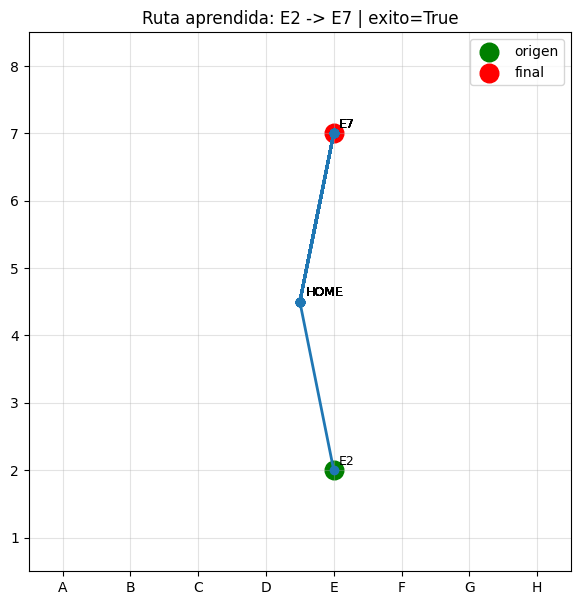

In [12]:
def accion_greedy(state):
    with torch.no_grad():
        state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        return int(policy_net(state_t).argmax(dim=1).item())


def generar_ruta(origen, destino, max_steps=MAX_STEPS):
    eval_env = BrazoAjedrezEnv(puntos, max_steps=max_steps, seed=SEED)
    state, _ = eval_env.reset_task(origen, destino)
    total_reward = 0.0
    success = False
    actions = []
    for _ in range(max_steps):
        action = accion_greedy(state)
        actions.append(action)
        state, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward
        success = bool(info["success"])
        if terminated or truncated:
            break
    return {
        "origen": origen.upper(),
        "destino": destino.upper(),
        "ruta": eval_env.route,
        "acciones": actions,
        "success": success,
        "reward": total_reward,
        "steps": len(actions),
    }


def graficar_ruta(resultado):
    ruta = resultado["ruta"]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_xlim(-0.5, 7.5)
    ax.set_ylim(-0.5, 7.5)
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticklabels(list("ABCDEFGH"))
    ax.set_yticklabels(list("12345678"))
    ax.grid(True, alpha=0.35)
    ax.set_title(f"Ruta aprendida: {resultado['origen']} -> {resultado['destino']} | exito={resultado['success']}")

    coords = []
    for sq in ruta:
        if sq == HOME_NODE:
            coords.append((3.5, 3.5))
        else:
            r, c = square_to_rc(sq)
            coords.append((c, r))

    xs, ys = zip(*coords)
    ax.plot(xs, ys, marker="o", linewidth=2)
    for i, (x, y) in enumerate(coords):
        label = ruta[i]
        ax.text(x + 0.08, y + 0.08, label, fontsize=9)
    ax.scatter(xs[0], ys[0], s=180, color="green", label="origen")
    ax.scatter(xs[-1], ys[-1], s=180, color="red", label="final")
    ax.legend()
    plt.show()


resultado_demo = generar_ruta("E2", "E7")
print(resultado_demo)
graficar_ruta(resultado_demo)

## 12. Evaluacion masiva de rutas

In [13]:
def evaluar_politica(n_pruebas=512):
    resultados = []
    for _ in range(n_pruebas):
        origen = random.choice(SQUARES)
        destino = random.choice(SQUARES)
        while destino == origen:
            destino = random.choice(SQUARES)
        resultados.append(generar_ruta(origen, destino))
    df = pd.DataFrame(resultados)
    print("Tasa de exito:", df["success"].mean())
    print("Pasos promedio:", df["steps"].mean())
    print("Reward promedio:", df["reward"].mean())
    return df, resultados


df_eval, rutas_eval = evaluar_politica(n_pruebas=512)
df_eval.head()

Tasa de exito: 1.0
Pasos promedio: 35.0
Reward promedio: 244.61998627369644


,origen,destino,ruta,acciones,success,reward,steps
0,G5,A8,"[G5, HOME, A8, HOME, A8, HOME, A8, HOME, A8, H...","[8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, ...",True,253.068322,35
1,H6,F1,"[H6, HOME, F1, HOME, F1, HOME, F1, HOME, F1, H...","[8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, ...",True,248.000017,35
2,H7,F3,"[H7, HOME, F3, HOME, F3, HOME, F3, HOME, F3, H...","[8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, ...",True,245.798782,35
3,D8,F1,"[D8, HOME, F1, HOME, F1, HOME, F1, HOME, F1, H...","[8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, ...",True,255.359140,35
4,E2,G5,"[E2, HOME, G5, HOME, G5, HOME, G5, HOME, G5, H...","[8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, 9, 8, ...",True,243.161868,35


## 13. Exportar rutas y `puntos_generados.txt`

In [15]:
def vecinos(square):
    r, c = square_to_rc(square)
    out = []
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0:
                continue
            nr, nc = r + dr, c + dc
            if 0 <= nr < 8 and 0 <= nc < 8:
                out.append(rc_to_square(nr, nc))
    return out


def generar_puntos_suavizados(alpha=0.88):
    generados = {}
    for sq in SQUARES:
        neigh = vecinos(sq)
        promedio_vecinos = np.mean([puntos[v] for v in neigh], axis=0) if neigh else puntos[sq]
        generados[sq] = alpha * puntos[sq] + (1.0 - alpha) * promedio_vecinos
    return generados


def exportar_resultados_rl():
    rutas = {}
    ejemplos = [
        ("E2", "E4"),
        ("E7", "E5"),
        ("A1", "H8"),
        ("H8", "A1"),
        ("B1", "C3"),
        ("E8", "G8"),
    ]
    for origen, destino in ejemplos:
        rutas[f"{origen}->{destino}"] = generar_ruta(origen, destino)

    with open(ROUTES_PATH, "w", encoding="utf-8") as f:
        json.dump(rutas, f, ensure_ascii=False, indent=2)

    puntos_generados = generar_puntos_suavizados(alpha=0.88)
    with open(PUNTOS_GENERADOS_PATH, "w", encoding="utf-8") as f:
        f.write("# Archivo experimental generado por el modulo de Aprendizaje por Refuerzo.\n")
        f.write("# NO reemplaza brazo_robotico/puntos.txt.\n")
        f.write("# Formato: CASILLA: base, codo, hombro\n")
        for sq in SQUARES:
            base, codo, hombro = puntos_generados[sq]
            f.write(f"{sq}: {base:.3f}, {codo:.3f}, {hombro:.3f}\n")

    print("Rutas generadas:", ROUTES_PATH)
    print("Puntos generados experimentales:", PUNTOS_GENERADOS_PATH)
    return rutas, puntos_generados


rutas_generadas, puntos_generados = exportar_resultados_rl()

Rutas generadas: /notebook/Aprendizaje_Por_Refuerzo/outputs/rutas_generadas.json
Puntos generados experimentales: /notebook/Aprendizaje_Por_Refuerzo/outputs/puntos_generados.txt
